# 18 - Multi-well / Field Study

**Part B - Petrophys Curriculum**

Single-well interpretation is where you learn the physics; **field studies** are where the
value is. This lesson scales the dynamic workflow across the **17-well Costa carbonate
field**, harmonises logs so wells can be compared fairly, and rolls the results up into a
**portfolio table** and a **cross-well summary figure**. Each Costa LAS file covers only
the **Kharaib-2 reservoir interval** of its well, so every number below describes that
interval, not the whole well.

## Learning goals

- Batch-process a whole field with `petrophys.workflow` (`BatchProcessor` /
  `process_las_directory`) and read a run `get_summary()`.
- Understand **multi-well log normalization** (`petrophys.preprocessing.normalization`) and why
  it is needed before cross-well comparison.
- Extract per-well reservoir metrics (net pay, average porosity, average `Sw`, an HCPV
  index) with `result.formation_summary()` into a single comparison table.
- Build a **cross-well summary plot** ranking the field's wells.

## Why this matters

Wells in one field are logged by different tools, crews, and vintages, so raw curve
distributions can drift from well to well for reasons that have nothing to do with the
rock. Two jobs follow:

1. **Normalization** removes acquisition drift so a `GR` of 40 means the same clay
   content in every well - a prerequisite for pooling data or ranking wells. But the
   drift has to be *diagnosed*, not assumed: part of a shifted distribution can be real
   geology, and normalizing it away destroys signal.
2. **Batch interpretation + roll-up** turns 17 separate analyses into one portfolio view:
   which wells carry the pay, how thick, how clean, how much hydrocarbon volume. That view
   drives development decisions.

### Prerequisites

Assumes the single-well interpretation concepts from Part A and the metrics they
produce (`PHIE`, `SW`, `NET_PAY`), plus formation summaries from lesson 11. The Costa
files are small (~430 samples each), so the whole field runs in seconds - no
subsampling needed.

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys as pp
from petrophys.workflow import BatchProcessor, process_las_directory
from petrophys.preprocessing.normalization import normalize_log

print("petrophys", pp.__version__)

costa_names = pp.list_samples("costa")
print("Costa field:", len(costa_names), "wells")
print(costa_names)

petrophys 3.0.0
Costa field: 17 wells
['HW-10', 'HW-24', 'HW-25', 'HW-26', 'HW-27', 'HW-28', 'HW-29', 'HW-3', 'HW-30', 'HW-31', 'HW-32', 'HW-4', 'HW-5', 'HW-6', 'HW-7', 'HW-8', 'HW-9']


## 1. Load the field

`list_samples("costa")` gives the 17 well names; `sample(name)` resolves each to its
bundled LAS path. We read them all with `pp.read` and attach the bundled Costa tops
(`formations_costa`). Each file covers only the **Kharaib-2 reservoir interval** of its
well, so the tops label the logged interval `KHARAIB-2`; the per-well summaries in
Section 4 use that label. (These files are compact, so we keep every depth sample; for
a large field you would subsample depth or process in chunks - and say so.)

In [2]:
costa_tops = pp.sample("formations_costa")
wells = [pp.read(pp.sample(name), formations=costa_tops) for name in costa_names]

overview = pd.DataFrame([
    {
        "well": w.name,
        "n_samples": w.n_samples,
        "top_ft": round(w.start_depth, 0),
        "bottom_ft": round(w.stop_depth, 0),
        "step_ft": w.step,
        "curves": ", ".join(w.curves[:5]) + ("..." if w.n_curves > 5 else ""),
    }
    for w in wells
])
print(overview.to_string(index=False))

 well  n_samples  top_ft  bottom_ft  step_ft                         curves
HW-10        381  8440.0     8630.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
HW-24        433  8364.0     8580.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
HW-25        413  8234.0     8440.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
HW-26        345  8456.0     8628.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
HW-27        409  8621.0     8825.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
HW-28        407  8524.0     8727.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
HW-29        445  8168.0     8390.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
 HW-3        431  7805.0     8020.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
HW-30        481  8320.0     8560.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
HW-31        421  8580.0     8790.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
HW-32        419  8371.0     8580.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
 HW-4        361  8150.0     8330.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
 HW-5       

## 2. Batch-process the whole field

`BatchProcessor` runs a workflow over many wells and collects a `BatchResult` per well
(with `success`, `errors`, `warnings`, and the interpretation `result`). With no
`workflow_func` supplied it runs the same **dynamic workflow** as `pp.interpret`, which
routes `VCL -> PHIE -> SW -> PERM` when inputs permit and sets the net-pay flags. One
difference matters: like the lower-level `pp.run_dynamic_workflow`, `BatchProcessor`
adds the calculated curves **to the `Well` objects you pass in** rather than to copies,
which avoids holding a second copy of every well. Loop over `pp.interpret` instead if
the input wells must stay untouched.

We pass the **Costa project cutoff set** (vcl 0.30 / phie 0.10 / sw 0.60 -
deliberately tighter than the generic carbonate standard of 0.045 / 0.70,
because Kharaib porosity runs high) - the same numbers case study 3 uses to
screen this field, so the two lessons are comparable knob-for-knob. No Rw is passed:
each Costa LAS header carries Rw and the temperature it was measured at, and the
workflow corrects that value to formation temperature (printed for one well below).

> **Aside - directory mode.** If your LAS files sit in a folder, `process_las_directory(
> directory, pattern="*.las")` does the same batch run straight from disk. Here we already
> hold `Well` objects, so we use `process_wells`.

In [3]:
# Costa project cutoffs (see cs2/cs3): tighter than the generic carbonate
# standard (STANDARD_CUTOFFS['carbonate'] = 0.30/0.045/0.70) because the
# Kharaib is a high-porosity carbonate and the screening targets quality rock.
COSTA_CUTOFFS = dict(vcl_cutoff=0.30, phie_cutoff=0.10, sw_cutoff=0.60)

# The COSTA wells are carbonates; lithology_domain defaults to clastic.
bp = BatchProcessor(config={**COSTA_CUTOFFS, "lithology_domain": "carbonate"})
print("cutoffs:", COSTA_CUTOFFS)
results = bp.process_wells(wells)

summary = bp.get_summary()
print("run summary:")
for k, v in summary.items():
    print("  %-14s %s" % (k, v))

cutoffs: {'vcl_cutoff': 0.3, 'phie_cutoff': 0.1, 'sw_cutoff': 0.6}


run summary:
  total_wells    17
  successful     17
  failed         0
  success_rate   1.0
  failed_wells   []


Every well should succeed. We keep each well's **interpretation result** for the
roll-up: `result.well` is the interpreted well carrying the new `PHIE`/`SW`/`NET_PAY`
curves, and the result also offers the trace and the per-formation summary.

In [4]:
processed = {r.well_name: r.result for r in results if r.success}
print("interpreted wells:", len(processed))

example = processed[wells[0].name]
added = [c for c in ("VCL", "PHIE", "SW", "PERM", "NET_ROCK", "NET_RES", "NET_PAY")
         if example.well.has_curve(c)]
print("curves added by the workflow:", added)
print("result.well is the input Well object:", example.well is wells[0])
steps = example.to_dataframe()
print(f"{example.well.name} Rw:", steps.loc[steps["Step"] == "rw", "Decisions"].iloc[0])

interpreted wells: 17
curves added by the workflow: ['VCL', 'PHIE', 'SW', 'PERM', 'NET_ROCK', 'NET_RES', 'NET_PAY']
result.well is the input Well object: True
HW-10 Rw: Rw directly corrected from LAS metadata: 0.1373 ohm.m @ 68F with Arps along the temperature profile


## 3. Multi-well log normalization

Before we compare wells, look at how their **GR distributions** differ. Even in the same
carbonate, the 5th-95th percentile GR window shifts well to well. Some of that shift may
be acquisition drift (tool, calibration, vintage, borehole) - but verify against
lithology before normalizing. HW-26's noticeably higher GR window, for instance, is
plausibly a real, more argillaceous section; forcing every well's P5-P95 onto one common
range would erase that geology. That is the classic normalization pitfall. With that
caveat stated, `normalize_log` rescales a curve so a chosen source window (here each
well's own P5-P95) maps to a common target range (0-100), aligning the distributions.

In [5]:
def gr_percentiles(w):
    gr = w.get("GR").data
    p5, p50, p95 = np.nanpercentile(gr, [5, 50, 95])
    return p5, p50, p95

raw_stats = pd.DataFrame([
    {"well": w.name, "GR_p5": round(a, 1), "GR_p50": round(b, 1), "GR_p95": round(c, 1)}
    for w in wells for (a, b, c) in [gr_percentiles(w)]
])
print("Raw GR percentiles (note the spread in P95):")
print(raw_stats.to_string(index=False))
print("\nP95 ranges from %.1f to %.1f API across the field."
      % (raw_stats.GR_p95.min(), raw_stats.GR_p95.max()))

Raw GR percentiles (note the spread in P95):
 well  GR_p5  GR_p50  GR_p95
HW-10    7.2     9.4    28.4
HW-24    5.1     7.7    30.6
HW-25    8.8    11.3    32.0
HW-26   11.6    23.7    69.9
HW-27   11.8    13.9    29.1
HW-28    8.8    11.2    38.5
HW-29    8.0    10.6    30.5
 HW-3    8.8    10.8    20.5
HW-30    8.7    10.5    29.2
HW-31    9.6    12.1    34.9
HW-32   10.1    13.0    37.7
 HW-4   10.0    12.0    33.0
 HW-5   13.6    16.6    42.9
 HW-6    7.6     9.9    28.0
 HW-7    7.0     9.6    33.0
 HW-8    9.3    11.2    32.5
 HW-9    6.5     7.9    24.4

P95 ranges from 20.5 to 69.9 API across the field.


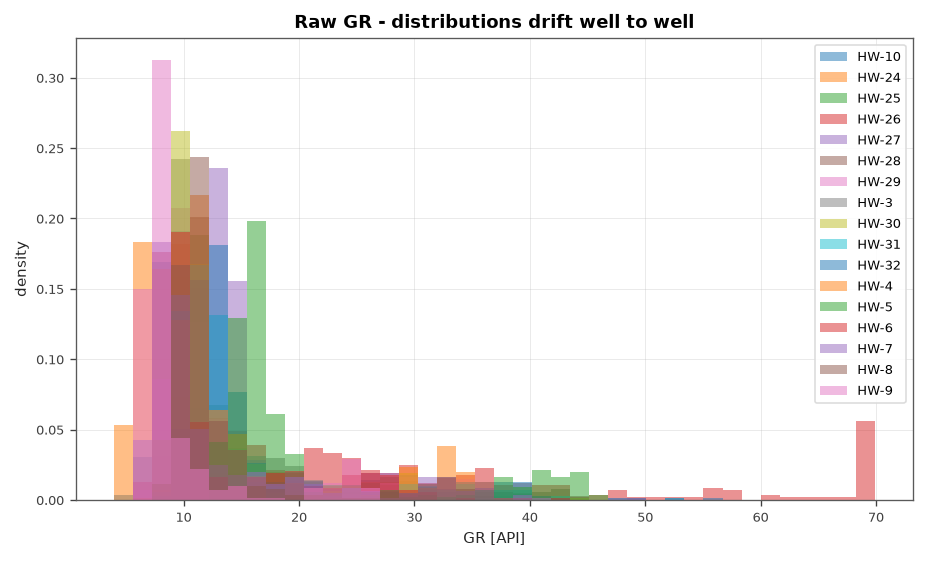

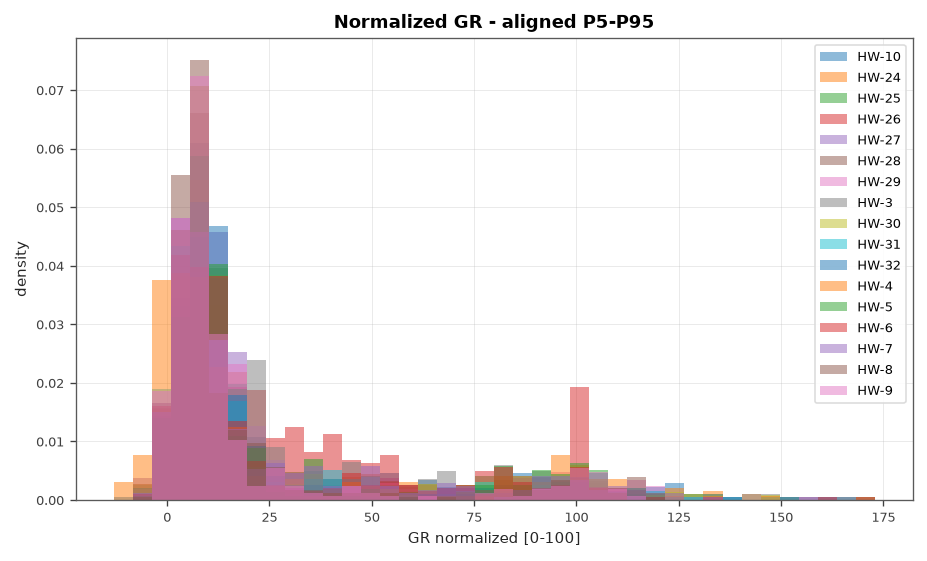

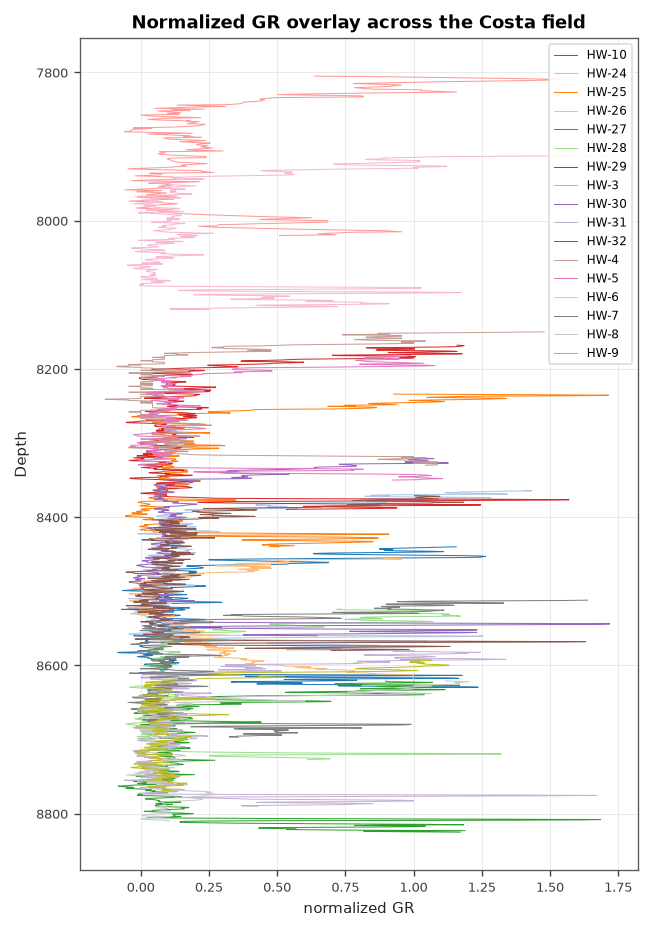

In [6]:
from petrophys.visualization import (
    create_histogram_comparison, create_multiwell_overlay,
)

# Normalize each well's GR so its own P5-P95 maps to 0-100.
gr_norm = {}
for w in wells:
    gr = w.get("GR").data
    lo, hi = np.nanpercentile(gr, [5, 95])
    gr_norm[w.name] = normalize_log(gr, log_min=0.0, log_max=100.0, log_low=lo, log_high=hi)

# Distribution comparison before vs after normalization (library histogram helper).
raw_dists = {w.name: w.get("GR").data for w in wells}
fig, ax = create_histogram_comparison(
    raw_dists, bins=40, density=True,
    xlabel="GR [API]", title="Raw GR - distributions drift well to well",
)
plt.show()

fig, ax = create_histogram_comparison(
    gr_norm, bins=40, density=True,
    xlabel="GR normalized [0-100]", title="Normalized GR - aligned P5-P95",
)
plt.show()

# Same story as a curve-vs-depth overlay: normalize=True robustly scales each
# well's GR so their shapes line up on one axis.
fig, ax = create_multiwell_overlay(
    wells, "GR", normalize=True,
    title="Normalized GR overlay across the Costa field", figsize=(6, 9),
)
plt.show()

After normalization the histograms line up: a given normalized GR now reads on the same
relative scale in every well - provided the shifts we removed really were acquisition
effects. That is the precondition for pooling wells or ranking them on the same scale.

## 4. Per-well reservoir metrics

Because every well carries the `KHARAIB-2` label, `result.formation_summary()` returns
one row per well with the library's standard interval metrics (thicknesses in the well's
depth unit - feet here):

- **Gross** - the logged Kharaib-2 thickness; **Net Pay** - the thickness flagged
  `NET_PAY` (pay samples x sample step);
- **NTG** - net pay / gross;
- **Avg PHIE** and **Avg Sw** - arithmetic means over the pay samples (**Avg Perm** is a
  geometric mean over pay);
- **HCPV** - a hydrocarbon pore-thickness index, `Avg PHIE x (1 - Avg Sw) x net pay`
  (per unit area; a relative volumetric indicator, not a booked reserve).

Gross is the thickness *labelled* `KHARAIB-2`. For most wells that is the whole file;
the cell also lists any well whose log continues below the Kharaib-2 base given in
the tops table - those deepest samples lie outside the summary. We collect the rows
into one portfolio table, then check the arithmetic for one well by hand from its
curves.

In [7]:
rows, below_base = [], {}
for name, result in processed.items():
    row = result.formation_summary().iloc[0]      # the single KHARAIB-2 row
    has_pay = row["Net Pay (ft)"] > 0
    if result.well.stop_depth > row["Bottom"]:
        below_base[name] = float(result.well.stop_depth - row["Bottom"])
    rows.append({
        "well": name,
        "formation": row["Formation"],
        "gross_ft": row["Gross (ft)"],
        "net_pay_ft": row["Net Pay (ft)"],
        "NTG": row["NTG"],
        "avg_PHIE": row["Avg PHIE"],
        "avg_Sw": row["Avg Sw"],
        "avg_perm_mD": row["Avg Perm (mD)"],
        "HCPV_ft": row["HCPV"] if has_pay else 0.0,   # no pay -> no hydrocarbon thickness
    })

portfolio = pd.DataFrame(rows).sort_values("HCPV_ft", ascending=False).reset_index(drop=True)
print(portfolio.round({"gross_ft": 1, "net_pay_ft": 1, "NTG": 2, "avg_PHIE": 3,
                       "avg_Sw": 3, "avg_perm_mD": 0, "HCPV_ft": 2}).to_string(index=False))
print("logged below the Kharaib-2 base (ft):",
      {name: round(extra, 1) for name, extra in below_base.items()} or "none")

 well formation  gross_ft  net_pay_ft  NTG  avg_PHIE  avg_Sw  avg_perm_mD  HCPV_ft
HW-29 KHARAIB-2     222.5       187.5 0.84     0.351   0.096       9800.0    59.55
HW-30 KHARAIB-2     240.5       208.5 0.87     0.305   0.155       8278.0    53.82
 HW-3 KHARAIB-2     215.5       180.5 0.84     0.274   0.102       8756.0    44.37
HW-25 KHARAIB-2     206.5       152.0 0.74     0.256   0.099       8438.0    35.04
HW-24 KHARAIB-2     216.5       150.0 0.69     0.238   0.265       1558.0    26.27
 HW-6 KHARAIB-2     208.5       140.5 0.67     0.240   0.257       1378.0    25.10
HW-32 KHARAIB-2     209.5       104.0 0.50     0.296   0.336       3003.0    20.41
HW-26 KHARAIB-2     172.5        40.0 0.23     0.152   0.420         51.0     3.53
HW-10 KHARAIB-2     190.5        11.0 0.06     0.242   0.507        545.0     1.31
HW-28 KHARAIB-2     203.5         4.0 0.02     0.142   0.543         59.0     0.26
 HW-8 KHARAIB-2     188.5         0.5 0.00     0.121   0.518         34.0     0.03
HW-2

In [8]:
# Hand check for the top-ranked well: the same metrics straight from its curves.
check = processed[portfolio.well.iloc[0]].well
pay = np.nan_to_num(check.get("NET_PAY").data) > 0.5
phie_pay, sw_pay = check.get("PHIE").data[pay], check.get("SW").data[pay]
net_pay = pay.sum() * check.step
print(f"{check.name}: {pay.sum()} pay samples x {check.step} ft = {net_pay:.1f} ft net pay")
print(f"  avg PHIE {np.nanmean(phie_pay):.3f}, avg Sw {np.nanmean(sw_pay):.3f}, "
      f"HCPV {np.nanmean(phie_pay) * (1 - np.nanmean(sw_pay)) * net_pay:.2f} ft")

HW-29: 375 pay samples x 0.5 ft = 187.5 ft net pay
  avg PHIE 0.351, avg Sw 0.096, HCPV 59.55 ft


### Field roll-up

Summing across the field gives the headline numbers, and counting pay-bearing wells shows
how concentrated the value is. A single 0.5-ft pay sample is enough to make a well
"pay-bearing", so the cell also counts the wells with at least 10 ft of net pay. Note
that the field average PHIE and Sw printed below are **unweighted means of the per-well
pay averages** - each pay-bearing well counts equally, regardless of how thick its pay
is (they are not net-pay-weighted).

In [9]:
pay_wells = portfolio[portfolio.net_pay_ft > 0]
print("wells in field             :", len(portfolio))
print("wells with any net pay     :", len(pay_wells))
print("wells with >= 10 ft net pay:", int((portfolio.net_pay_ft >= 10).sum()))
print("total net pay (ft)         : %.1f" % portfolio.net_pay_ft.sum())
print("field average PHIE (pay)   : %.3f" % pay_wells.avg_PHIE.mean())
print("field average Sw (pay)     : %.3f" % pay_wells.avg_Sw.mean())
print("total HCPV index (ft)      : %.1f" % portfolio.HCPV_ft.sum())
top3 = pay_wells.nlargest(3, "HCPV_ft").well.tolist()
print("top 3 wells by HCPV index  :", top3)

wells in field             : 17
wells with any net pay     : 12
wells with >= 10 ft net pay: 9
total net pay (ft)         : 1179.0
field average PHIE (pay)   : 0.229
field average Sw (pay)     : 0.324
total HCPV index (ft)      : 269.7
top 3 wells by HCPV index  : ['HW-29', 'HW-30', 'HW-3']


## 5. Cross-well summary plot

Two charts rank the field. The first is a **ranked horizontal bar chart of net pay per
well** (single color, widest bar at top) - the quantity view. The second shows the
pay-bearing wells as **grouped ranked bars**: the HCPV index alongside average PHIE x100
and average Sw x100 (scaled so all three share one axis), ranked by HCPV. Read
together they separate thin-but-rich from thick-but-lean wells.

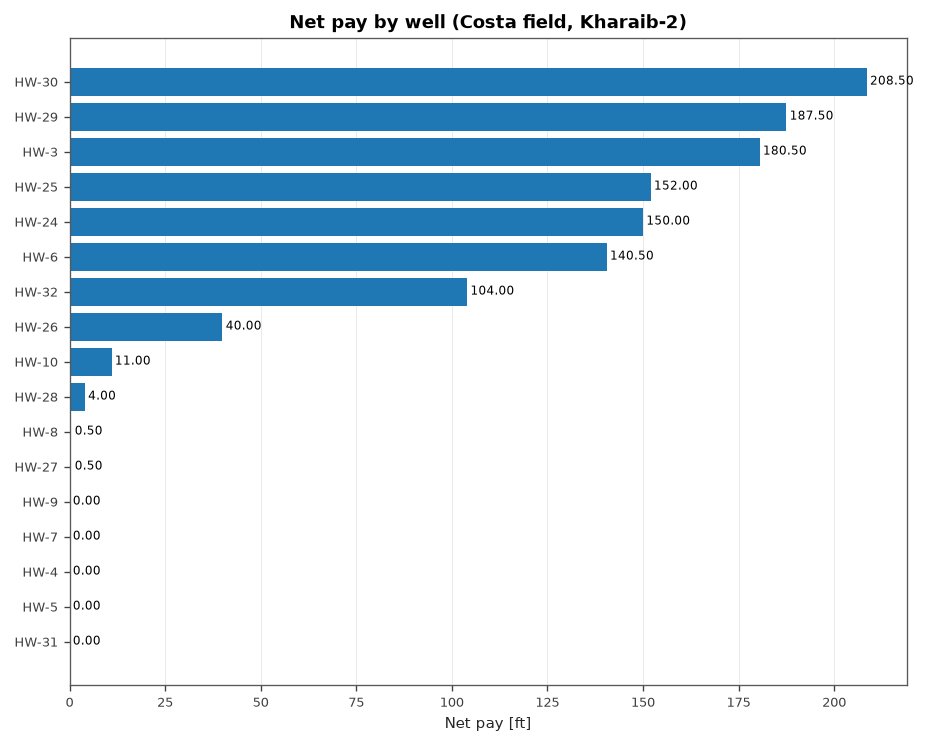

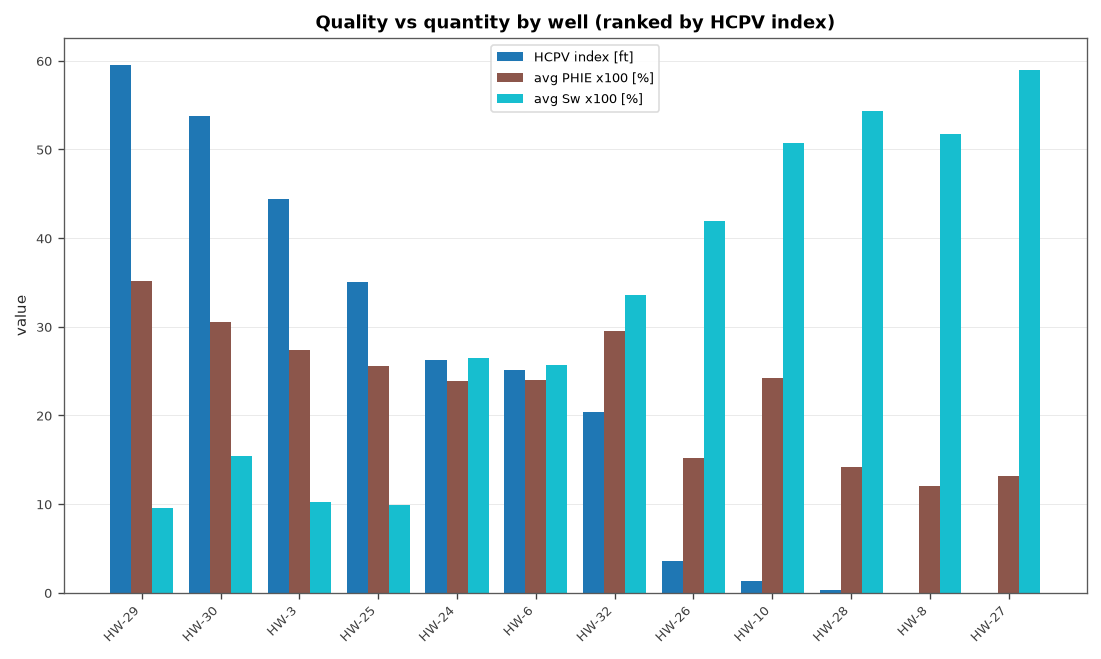

In [10]:
from petrophys.visualization import create_bar_comparison

# Left view: net pay per well, horizontal ranked bars (widest at top).
fig, ax = create_bar_comparison(
    portfolio.well.tolist(), portfolio.net_pay_ft.tolist(),
    horizontal=True, sort_by=0, descending=True, value_labels=True,
    xlabel="Net pay [ft]", title="Net pay by well (Costa field, Kharaib-2)",
    figsize=(9, 7),
)
plt.show()

# Right view: the quality-vs-quantity roll-up as grouped ranked bars -
# HCPV index (quantity) alongside average porosity scaled to the same axis
# (x100, quality) and average Sw (x100), ranked by HCPV.
pw = portfolio[portfolio.net_pay_ft > 0]
grouped = {
    "HCPV index [ft]": pw.HCPV_ft.tolist(),
    "avg PHIE x100 [%]": (pw.avg_PHIE * 100).tolist(),
    "avg Sw x100 [%]": (pw.avg_Sw * 100).tolist(),
}
fig, ax = create_bar_comparison(
    pw.well.tolist(), grouped, sort_by=0, descending=True,
    ylabel="value", title="Quality vs quantity by well (ranked by HCPV index)",
    figsize=(11, 6),
)
plt.show()

## Pitfalls & parameter choices

- **`BatchProcessor` swallows per-well failures.** Always inspect `get_summary()` and
  `BatchResult.errors`; a `success_rate` below 1.0 means some wells were skipped, not that
  they were zero-pay.
- **`BatchProcessor` modifies the wells you pass.** Like `pp.run_dynamic_workflow`, it
  adds the calculated curves to the input `Well` objects (`result.well is wells[i]`),
  whereas `pp.interpret` works on a copy. Running the batch a second time on the same
  objects would start from wells that already carry the first run's curves - re-read the
  files first, or loop over `pp.interpret`.
- **Each Costa file is the Kharaib-2 interval only.** Gross, NTG and net pay describe
  the logged Kharaib-2 interval, not the whole well; do not compare them with whole-well
  totals from other fields.
- **Normalize before pooling, not after computing.** Normalization is an input-conditioning
  step for cross-well comparison; do not normalize an already-interpreted output curve.
- **Same cutoffs, different recipe: expect deltas vs CS3.** Case study 3 screens
  this field with a hand-rolled chain (header Archie constants, Arps-corrected Rw) at the
  same cutoffs. Its per-well net pay differs somewhat from this batch run - that residual
  is the *recipe* (porosity chain, Archie constants), not the cutoffs.
- **Watch the depth unit.** Costa wells are in **feet**; net pay and HCPV inherit that
  unit. Do not mix them with metric (GeoLink) wells without converting.
- **The HCPV index is relative.** `Avg PHIE x (1 - Avg Sw) x net pay` is a per-unit-area
  screening indicator for ranking wells, not a volumetric reserve (no area, Bo, or
  recovery factor).

## Recap

- `BatchProcessor` (or `process_las_directory`) runs the dynamic workflow across a whole
  field and reports a `get_summary()`; keep each result for the roll-up.
- **Log normalization** (`normalize_log`) removes acquisition drift so wells share one
  scale - the precondition for fair cross-well comparison, once you have checked that
  the shift is not geology.
- With the Kharaib-2 tops attached, `result.formation_summary()` yields per-well
  **net pay, average porosity/Sw, permeability and an HCPV index**, which pool into a
  portfolio table and field totals.
- A **cross-well summary plot** turns 17 analyses into one ranking that highlights where
  the pay and hydrocarbon volume concentrate.

## Try it yourself

> **Exercise 1.** Re-run the portfolio with stricter cutoffs by passing a `config` to
> `BatchProcessor(config={...})` (e.g. tighter `phie_cutoff`). Re-read the wells first
> (see the pitfalls). How does total net pay respond, and which marginal wells drop out?
>
> **Exercise 2.** Replace the per-well GR normalization window with a **single field
> reference** (one well's P5-P95 for all). Does that change the ranking of borderline
> wells?
>
> **Exercise 3.** The portfolio already carries `avg_perm_mD` (geometric mean over pay).
> Add it as another bar series in the grouped quality-vs-quantity chart (scale it to
> share the axis, the way PHIE is shown as PHIE x100 - or swap it in for the Sw series).
> Do the highest-HCPV wells also have the best flow capacity?

## What's next

Continue with **19_llm_context_generation.ipynb**, which turns interpreted wells into
compact, auditable JSON context for LLM and review workflows. Lesson
**20_mcp_server.ipynb** then lets an LLM client drive the same workflow through the
Model Context Protocol. For a deeper look at this field, case studies 2 and 3 work
through Costa carbonate rock typing and a full 17-well screening.